[LightGBM] [Info] Number of positive: 3154, number of negative: 24845
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008349 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 256
[LightGBM] [Info] Number of data points in the train set: 27999, number of used features: 18
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.112647 -> initscore=-2.063985
[LightGBM] [Info] Start training from score -2.063985
--- DÜZELTİLMİŞ TEST SETİ ROC-AUC SKORLARI ---
LightGBM ROC-AUC: 0.7460
CatBoost ROC-AUC: 0.7784


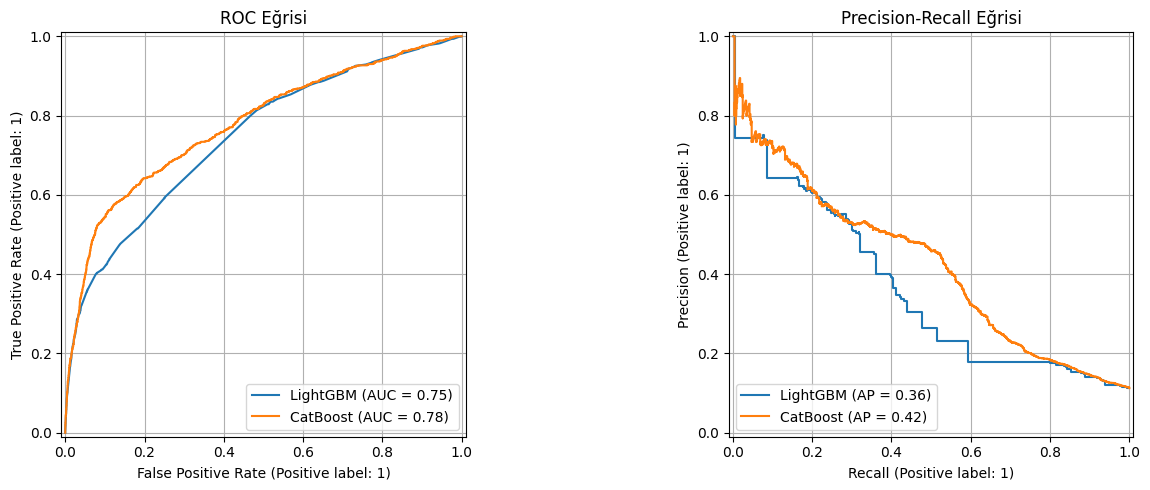


✅ model.joblib dosyası CatBoost modeli ile başarıyla oluşturuldu!


In [15]:
!pip install catboost lightgbm joblib -q

import zipfile
import urllib.request
import os
import joblib
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score, classification_report, RocCurveDisplay, PrecisionRecallDisplay
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
import lightgbm as lgb
from catboost import CatBoostClassifier
import matplotlib.pyplot as plt

# 1. Veri Yükleme
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
zip_path = "bank.zip"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("bank_raw")
    with zipfile.ZipFile("bank_raw/bank-additional.zip", 'r') as zip_ref:
        zip_ref.extractall("bank_data")

df = pd.read_csv("bank_data/bank-additional/bank-additional-full.csv", sep=';')

# 2. Temizlik ve Sızıntı Önleme
df = df.drop_duplicates().reset_index(drop=True)
if 'duration' in df.columns:
    df = df.drop(columns=['duration'])

df['y'] = (df['y'] == 'yes').astype(int)

# 3. Öznitelik Mühendisliği (Zaman Kaymasına Dirençli Değişkenler)
df['previously_contacted'] = (df['pdays'] != 999).astype(int)
df['pdays_cleaned'] = df['pdays'].apply(lambda x: 0 if x == 999 else x)
df['total_contacts'] = df['campaign'] + df['previous']
df['previous_success_ratio'] = df['poutcome'].apply(lambda x: 1 if x == 'success' else 0)

# Ham makro değişkenleri çıkarma (Zaman kayması çöküşünü önleme)
macro_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
df_tree = df.drop(columns=macro_cols)

# 4. Veri Bölme & Kategorik Kodlama
X = df_tree.drop(columns=['y'])
y = df_tree['y']

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[cat_cols] = encoder.fit_transform(X[cat_cols])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42, stratify=y_train)

# 5. Model Eğitimi (LightGBM & CatBoost)
scale_pos_weight = (len(y_tr) - sum(y_tr)) / sum(y_tr)

lgb_model = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=20,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

lgb_model.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(30, verbose=False)]
)

cat_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.03,
    depth=5,
    scale_pos_weight=scale_pos_weight,
    random_seed=42,
    verbose=0
)

cat_model.fit(X_tr, y_tr, eval_set=(X_val, y_val), early_stopping_rounds=30)

# 6. Sonuçlar
y_pred_lgb = lgb_model.predict_proba(X_test)[:, 1]
y_pred_cat = cat_model.predict_proba(X_test)[:, 1]

print(f"--- DÜZELTİLMİŞ TEST SETİ ROC-AUC SKORLARI ---")
print(f"LightGBM ROC-AUC: {roc_auc_score(y_test, y_pred_lgb):.4f}")
print(f"CatBoost ROC-AUC: {roc_auc_score(y_test, y_pred_cat):.4f}")

# Grafikler
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_test, y_pred_lgb, ax=ax[0], name='LightGBM')
RocCurveDisplay.from_predictions(y_test, y_pred_cat, ax=ax[0], name='CatBoost')
ax[0].set_title('ROC Eğrisi')
ax[0].grid(True)

PrecisionRecallDisplay.from_predictions(y_test, y_pred_lgb, ax=ax[1], name='LightGBM')
PrecisionRecallDisplay.from_predictions(y_test, y_pred_cat, ax=ax[1], name='CatBoost')
ax[1].set_title('Precision-Recall Eğrisi')
ax[1].grid(True)

plt.tight_layout()
plt.show()

# 7. Modeli Servis İçin Dışa Aktarma (model.joblib)
artifacts = {
    "model": cat_model,
    "encoder": encoder,
    "cat_cols": cat_cols
}

joblib.dump(artifacts, "model.joblib")
print("\n✅ model.joblib dosyası CatBoost modeli ile başarıyla oluşturuldu!")